# Notebook 10 — XAI Evaluation Framework

| Metric | Question answered | Better |
|---|---|---|
| Faithfulness | Do top-attributed sensors actually drive the prediction? | Higher peak RMSE drop |
| Stability | Do similar inputs produce similar explanations? | Lower Lipschitz score |
| Complexity | Are explanations focused on a few key sensors? | Higher Gini coefficient |

### Models evaluated
- LSTM, 1D-CNN, Transformer

### XAI methods evaluated
- GradientSHAP, Integrated Gradients
- Attention weights (Transformer only, faithfulness and complexity only)


In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from src.utils.config import DATA_PROC, OUT_MODELS, OUT_FIGURES
from src.models.lstm        import LSTMModel
from src.models.cnn1d       import CNN1DModel
from src.models.transformer import TransformerModel
from src.explainability.gradientshap         import GradientSHAPExplainer
from src.explainability.integrated_gradients import IGExplainer
from src.explainability.attention_viz        import AttentionVisualiser
from src.evaluation.xai_metrics import (
    faithfulness_deletion, faithfulness_random_baseline,
    stability_score, complexity_score, print_xai_evaluation_table
)

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': 'white'})

SUBSET  = 'FD001'
DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SENSORS = ['s_2','s_3','s_4','s_7','s_8','s_9','s_11',
           's_12','s_13','s_14','s_15','s_17','s_20','s_21']
COLORS  = {'lstm':'#2a78d6','cnn1d':'#1baf7a','transformer':'#534AB7'}
LABELS  = {'lstm':'LSTM','cnn1d':'1D-CNN','transformer':'Transformer'}
print(f'Device: {DEVICE}')

Device: cpu


## 1 · Load models and test data

In [2]:
proc   = DATA_PROC / SUBSET
X_test = np.load(proc / 'X_test.npy')   # (100, 30, 14)
y_test = np.load(proc / 'y_test.npy')   # (100,)

def load_model(cls, name):
    m = cls()
    ckpt = OUT_MODELS / f'{name}_{SUBSET}_best.pt'
    m.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    return m.to(DEVICE).eval()

models = {
    'lstm'       : load_model(LSTMModel,        'lstm'),
    'cnn1d'        : load_model(CNN1DModel,        'cnn1d'),
    'transformer': load_model(TransformerModel,  'transformer'),
}
print('All models loaded ')
print(f'Test windows: {X_test.shape}   RUL range: [{y_test.min():.0f}, {y_test.max():.0f}]')

All models loaded 
Test windows: (100, 30, 14)   RUL range: [7, 125]


## 2 · Compute attributions for all model × method combinations


In [3]:
attributions = {}   # attributions[model_name][method_name] = (100, 30, 14)

for model_name, model in models.items():
    attributions[model_name] = {}
    print(f'\n── {LABELS[model_name]} ─────────────────────────────')

    # GradientSHAP
    print('  Computing GradientSHAP...')
    shap_exp = GradientSHAPExplainer(model, DEVICE, n_samples=30)
    shap_attrs = shap_exp.attribute_batch(X_test)
    attributions[model_name]['shap'] = shap_attrs
    print(f'  SHAP done. Shape: {shap_attrs.shape}')

    # Integrated Gradients
    print('  Computing Integrated Gradients...')
    ig_exp = IGExplainer(model, DEVICE, n_steps=50)
    ig_attrs, ig_deltas = ig_exp.attribute_batch(X_test, verbose=False)
    attributions[model_name]['ig'] = ig_attrs
    print(f'  IG done. Shape: {ig_attrs.shape}  mean_delta={ig_deltas.mean():.4f}')

# Attention weights for Transformer (sensor-level: mean across heads and layers)
print('\n── Transformer Attention ────────────────────')
attn_viz = AttentionVisualiser(models['transformer'], DEVICE)
attn_sensor_attrs = []
for i in range(len(X_test)):
    w = torch.tensor(X_test[i:i+1], dtype=torch.float32)
    wts_list = attn_viz.get_weights(w)   # list of 3 arrays (4,30,30)
    # Average all layers and heads → (30,30) attention map
    avg_attn = np.mean([w.mean(axis=0) for w in wts_list], axis=0)  # (30,30)
    # Row-sum gives how much each query cycle was attended TO by all others
    cycle_importance = avg_attn.mean(axis=0)   # (30,) — importance per key cycle
    # Broadcast to sensor dimension: each sensor in important cycles gets credit
    sensor_attr = np.outer(cycle_importance, np.ones(14)) * np.abs(X_test[i])
    attn_sensor_attrs.append(sensor_attr)
attributions['transformer']['attention'] = np.stack(attn_sensor_attrs)  # (100,30,14)
print(f'Attention sensor attributions done. Shape: {attributions["transformer"]["attention"].shape}')


── LSTM ─────────────────────────────
  Computing GradientSHAP...
  GradientSHAP: 10/100 windows done
  GradientSHAP: 20/100 windows done
  GradientSHAP: 30/100 windows done
  GradientSHAP: 40/100 windows done
  GradientSHAP: 50/100 windows done
  GradientSHAP: 60/100 windows done
  GradientSHAP: 70/100 windows done
  GradientSHAP: 80/100 windows done
  GradientSHAP: 90/100 windows done
  GradientSHAP: 100/100 windows done
  SHAP done. Shape: (100, 30, 14)
  Computing Integrated Gradients...
  IG done. Shape: (100, 30, 14)  mean_delta=0.0010

── 1D-CNN ─────────────────────────────
  Computing GradientSHAP...
  GradientSHAP: 10/100 windows done
  GradientSHAP: 20/100 windows done
  GradientSHAP: 30/100 windows done
  GradientSHAP: 40/100 windows done
  GradientSHAP: 50/100 windows done
  GradientSHAP: 60/100 windows done
  GradientSHAP: 70/100 windows done
  GradientSHAP: 80/100 windows done
  GradientSHAP: 90/100 windows done
  GradientSHAP: 100/100 windows done
  SHAP done. Shape: (

## 3 · Faithfulness : deletion curves

In [4]:
faith_results = {}

for model_name, model in models.items():
    faith_results[model_name] = {}
    for method_name, attrs in attributions[model_name].items():
        print(f'Faithfulness: {LABELS[model_name]} * {method_name}...')
        result = faithfulness_deletion(model, X_test, attrs, DEVICE)
        faith_results[model_name][method_name] = result

# Random baseline
faith_random = {}
for model_name, model in models.items():
    faith_random[model_name] = faithfulness_random_baseline(model, X_test, DEVICE)

print('\nFaithfulness computation complete ')

Faithfulness: LSTM * shap...
Faithfulness: LSTM * ig...
Faithfulness: 1D-CNN * shap...
Faithfulness: 1D-CNN * ig...
Faithfulness: Transformer * shap...
Faithfulness: Transformer * ig...
Faithfulness: Transformer * attention...

Faithfulness computation complete 


## 4 · Faithfulness : plot deletion curves

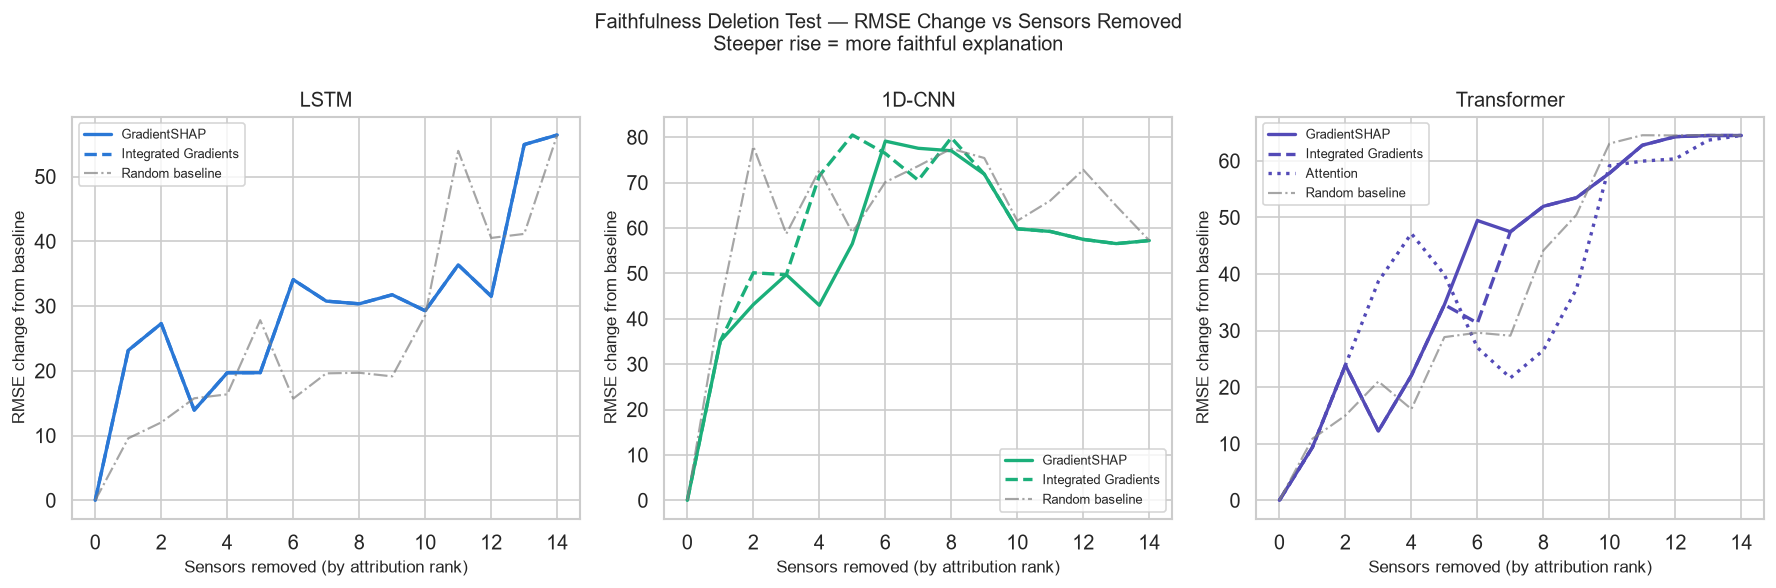

Peak RMSE drop (faithfulness):
Model            SHAP AUC     IG AUC   Random AUC   SHAP early
----------------------------------------------------
  LSTM            29.3582    29.3582      24.8659      13.9301
  1D-CNN          56.7740    60.5310      64.4364      49.7168
  Transformer     41.8682    40.5739      38.1555      12.2382


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
method_styles = {'shap': ('-', 'GradientSHAP'), 'ig': ('--', 'Integrated Gradients'),
                 'attention': (':', 'Attention')}

for ax, (model_name, model_label) in zip(axes, LABELS.items()):
    for method_name, (ls, method_label) in method_styles.items():
        if method_name not in faith_results[model_name]:
            continue
        r = faith_results[model_name][method_name]
        ax.plot(r['sensors_removed'], r['rmse_curve'],
                linestyle=ls, color=COLORS[model_name], linewidth=2,
                label=method_label)

    # Random baseline
    rnd = faith_random[model_name]
    ax.plot(rnd['sensors_removed'], rnd['rmse_curve'],
            linestyle='-.', color='grey', linewidth=1.3, alpha=0.7,
            label='Random baseline')

    ax.set_xlabel('Sensors removed (by attribution rank)', fontsize=10)
    ax.set_ylabel('RMSE change from baseline', fontsize=10)
    ax.set_title(f'{model_label}', fontsize=12)
    ax.legend(fontsize=8)
    ax.set_xticks(range(0, 15, 2))

fig.suptitle('Faithfulness Deletion Test — RMSE Change vs Sensors Removed\n'
             'Steeper rise = more faithful explanation', fontsize=12)
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'xai_eval_faithfulness.png', bbox_inches='tight')
plt.show()

# Print peak RMSE values
print(f'Peak RMSE drop (faithfulness):')
print(f'{"Model":<14} {"SHAP AUC":>10} {"IG AUC":>10} {"Random AUC":>12} {"SHAP early":>12}')
print('-'*52)
for model_name in models:
    shap_auc   = faith_results[model_name].get('shap',{}).get('auc', 0)
    ig_auc     = faith_results[model_name].get('ig',{}).get('auc', 0)
    rnd_auc    = faith_random[model_name]['auc']
    # Early RMSE = RMSE after removing just top 3 sensors
    shap_early = faith_results[model_name].get('shap',{}).get('rmse_curve',[0]*4)[3]
    print(f'  {LABELS[model_name]:<12} {shap_auc:>10.4f} {ig_auc:>10.4f} '
          f'{rnd_auc:>12.4f} {shap_early:>12.4f}')

## 5 · Stability: Lipschitz scores

In [6]:
stab_results = {}

for model_name, model in models.items():
    stab_results[model_name] = {}

    # SHAP stability
    print(f'\nStability (SHAP): {LABELS[model_name]}...')
    shap_exp = GradientSHAPExplainer(model, DEVICE, n_samples=20)
    stab_shap = stability_score(
        explainer_fn = lambda w, e=shap_exp: e.attribute(w),
        X = X_test, n_samples=10, noise_std=0.05
    )
    stab_results[model_name]['shap'] = stab_shap
    print(f'  Mean Lipschitz: {stab_shap["mean_lipschitz"]:.4f}')

    # IG stability
    print(f'Stability (IG): {LABELS[model_name]}...')
    ig_exp = IGExplainer(model, DEVICE, n_steps=30)
    stab_ig = stability_score(
        explainer_fn = lambda w, e=ig_exp: e.attribute(w)[0],
        X = X_test, n_samples=10, noise_std=0.05
    )
    stab_results[model_name]['ig'] = stab_ig
    print(f'  Mean Lipschitz: {stab_ig["mean_lipschitz"]:.4f}')

print('\nStability computation complete ')


Stability (SHAP): LSTM...
  Stability: 5/20 windows  running mean=15.7824
  Stability: 10/20 windows  running mean=14.8028
  Stability: 15/20 windows  running mean=14.6290
  Stability: 20/20 windows  running mean=13.5079
  Mean Lipschitz: 13.5079
Stability (IG): LSTM...
  Stability: 5/20 windows  running mean=15.1863
  Stability: 10/20 windows  running mean=14.6897
  Stability: 15/20 windows  running mean=13.9705
  Stability: 20/20 windows  running mean=12.4966
  Mean Lipschitz: 12.4966

Stability (SHAP): 1D-CNN...
  Stability: 5/20 windows  running mean=14.3606
  Stability: 10/20 windows  running mean=14.2408
  Stability: 15/20 windows  running mean=14.1819
  Stability: 20/20 windows  running mean=13.1499
  Mean Lipschitz: 13.1499
Stability (IG): 1D-CNN...
  Stability: 5/20 windows  running mean=20.5403
  Stability: 10/20 windows  running mean=20.2203
  Stability: 15/20 windows  running mean=20.0193
  Stability: 20/20 windows  running mean=18.5968
  Mean Lipschitz: 18.5968

Stability

## 6 · Stability: plot Lipschitz distributions

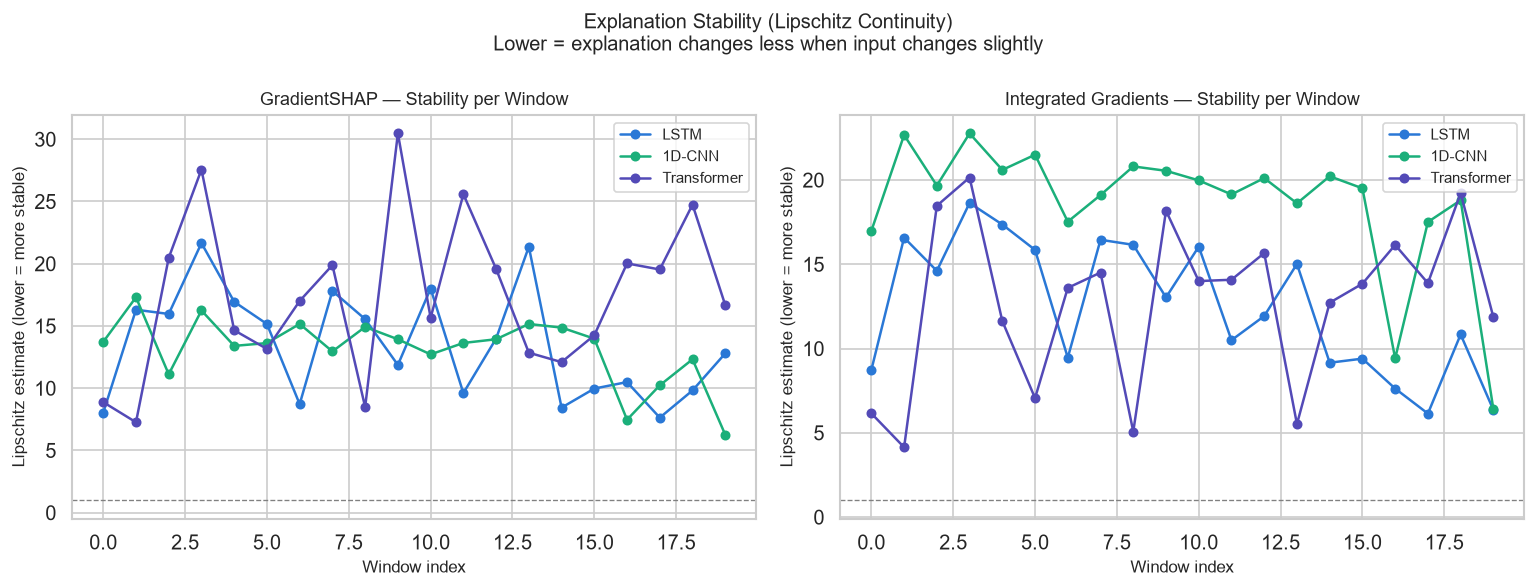


Mean Lipschitz (stability):
Model                SHAP         IG
------------------------------------
  LSTM            13.5079    12.4966
  1D-CNN          13.1499    18.5968
  Transformer     17.4438    12.7979


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, method in zip(axes, ['shap', 'ig']):
    method_label = 'GradientSHAP' if method == 'shap' else 'Integrated Gradients'
    for model_name in models:
        scores = stab_results[model_name][method]['lipschitz_scores']
        ax.plot(range(len(scores)), scores, marker='o', markersize=5,
                color=COLORS[model_name], linewidth=1.5, label=LABELS[model_name])
    ax.set_xlabel('Window index', fontsize=10)
    ax.set_ylabel('Lipschitz estimate (lower = more stable)', fontsize=10)
    ax.set_title(f'{method_label} — Stability per Window', fontsize=11)
    ax.legend(fontsize=9)
    ax.axhline(1.0, color='grey', linestyle='--', linewidth=0.8, label='Reference')

fig.suptitle('Explanation Stability (Lipschitz Continuity)\n'
             'Lower = explanation changes less when input changes slightly', fontsize=12)
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'xai_eval_stability.png', bbox_inches='tight')
plt.show()

print(f'\n{"Mean Lipschitz (stability):":}')
print(f'{"Model":<14} {"SHAP":>10} {"IG":>10}')
print('-'*36)
for model_name in models:
    s = stab_results[model_name]['shap']['mean_lipschitz']
    g = stab_results[model_name]['ig']['mean_lipschitz']
    print(f'  {LABELS[model_name]:<12} {s:>10.4f} {g:>10.4f}')

## 7 · Complexity: Gini coefficients

In [8]:
comp_results = {}

for model_name in models:
    comp_results[model_name] = {}
    for method_name, attrs in attributions[model_name].items():
        result = complexity_score(attrs)
        comp_results[model_name][method_name] = result
        print(f'{LABELS[model_name]} × {method_name:<12}  '
              f'Gini={result["mean_gini"]:.4f}  '
              f'Top1={result["top1_fraction"]*100:.1f}%  '
              f'Top3={result["top3_fraction"]*100:.1f}%')

LSTM × shap          Gini=0.2407  Top1=13.4%  Top3=35.6%
LSTM × ig            Gini=0.2414  Top1=13.4%  Top3=35.7%
1D-CNN × shap          Gini=0.3034  Top1=15.1%  Top3=38.6%
1D-CNN × ig            Gini=0.2690  Top1=13.8%  Top3=36.0%
Transformer × shap          Gini=0.2588  Top1=14.3%  Top3=37.5%
Transformer × ig            Gini=0.2663  Top1=14.6%  Top3=38.0%
Transformer × attention     Gini=0.1877  Top1=10.7%  Top3=31.2%


## 8 · Complexity : Gini box plots

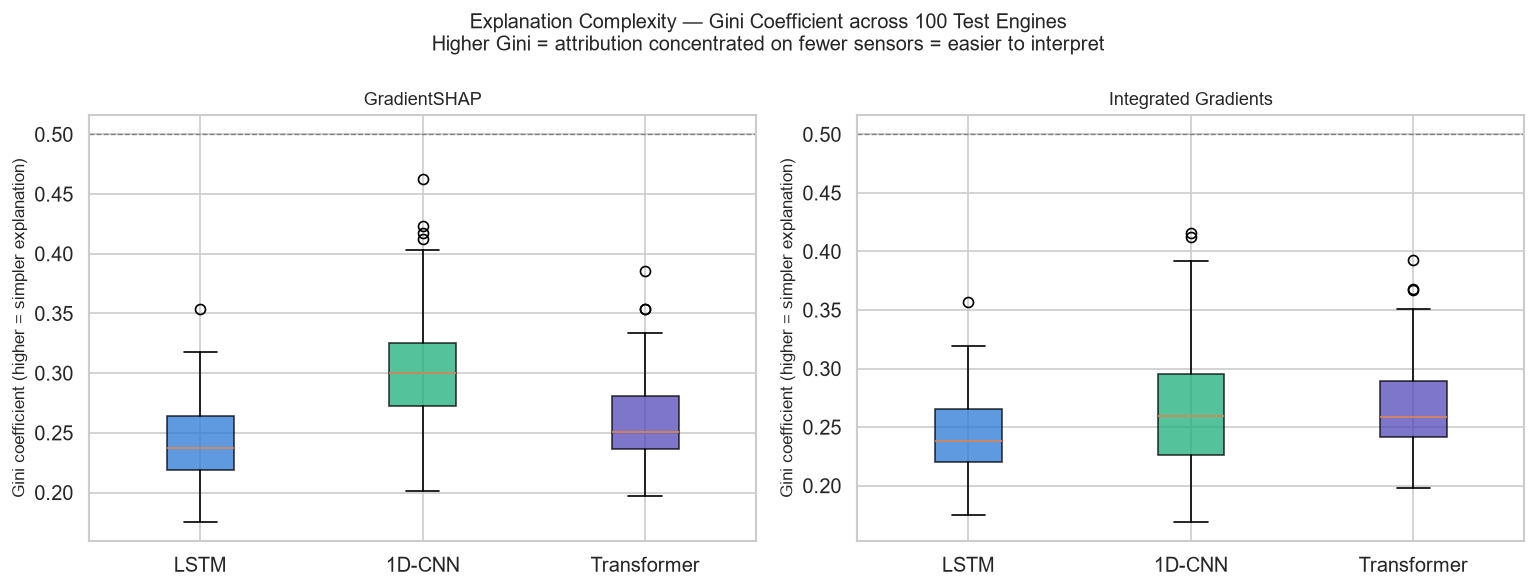

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, method in zip(axes, ['shap', 'ig']):
    method_label = 'GradientSHAP' if method == 'shap' else 'Integrated Gradients'
    data    = [comp_results[m][method]['gini_per_window'] for m in models]
    labels  = [LABELS[m] for m in models]
    colors  = [COLORS[m] for m in models]

    bp = ax.boxplot(data, patch_artist=True, tick_labels=labels)
    for patch, col in zip(bp['boxes'], colors):
        patch.set_facecolor(col)
        patch.set_alpha(0.75)

    ax.set_ylabel('Gini coefficient (higher = simpler explanation)', fontsize=10)
    ax.set_title(f'{method_label}', fontsize=11)
    ax.axhline(0.5, color='grey', linestyle='--', linewidth=0.8)

fig.suptitle('Explanation Complexity — Gini Coefficient across 100 Test Engines\n'
             'Higher Gini = attribution concentrated on fewer sensors = easier to interpret',
             fontsize=12)
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'xai_eval_complexity.png', bbox_inches='tight')
plt.show()

## 9 · Full evaluation summary table

In [10]:
# Build combined results dict for the summary printer
eval_results = {}
for model_name in models:
    eval_results[LABELS[model_name]] = {}
    for method_name in attributions[model_name]:
        eval_results[LABELS[model_name]][method_name.upper()] = {
            'faithfulness': faith_results[model_name].get(method_name, {'peak_rmse': 0}),
            'stability'   : stab_results[model_name].get(method_name, {'mean_lipschitz': 0}),
            'complexity'  : comp_results[model_name][method_name],
        }

print_xai_evaluation_table(eval_results)


                   XAI EVALUATION FRAMEWORK — RESULTS                   
Model          Method              Faithful↑   Stable↓    Gini↑    Top3%
------------------------------------------------------------------------
  LSTM         SHAP                  56.4188   13.5079   0.2407    35.6%
  LSTM         IG                    56.4188   12.4966   0.2414    35.7%
  1D-CNN       SHAP                  79.1506   13.1499   0.3034    38.6%
  1D-CNN       IG                    80.5069   18.5968   0.2690    36.0%
  Transformer  SHAP                  64.4931   17.4438   0.2588    37.5%
  Transformer  IG                    64.4931   12.7979   0.2663    38.0%
  Transformer  ATTENTION             64.4931    0.0000   0.1877    31.2%
Faithful↑ : peak RMSE drop when top sensors removed (higher = more faithful)
Stable↓   : mean Lipschitz estimate (lower = more stable)
Gini↑     : attribution sparsity (higher = simpler explanation)
Top3%     : % of importance held by top 3 sensors (higher = more focus

## 10 · Radar chart overall XAI profile per model

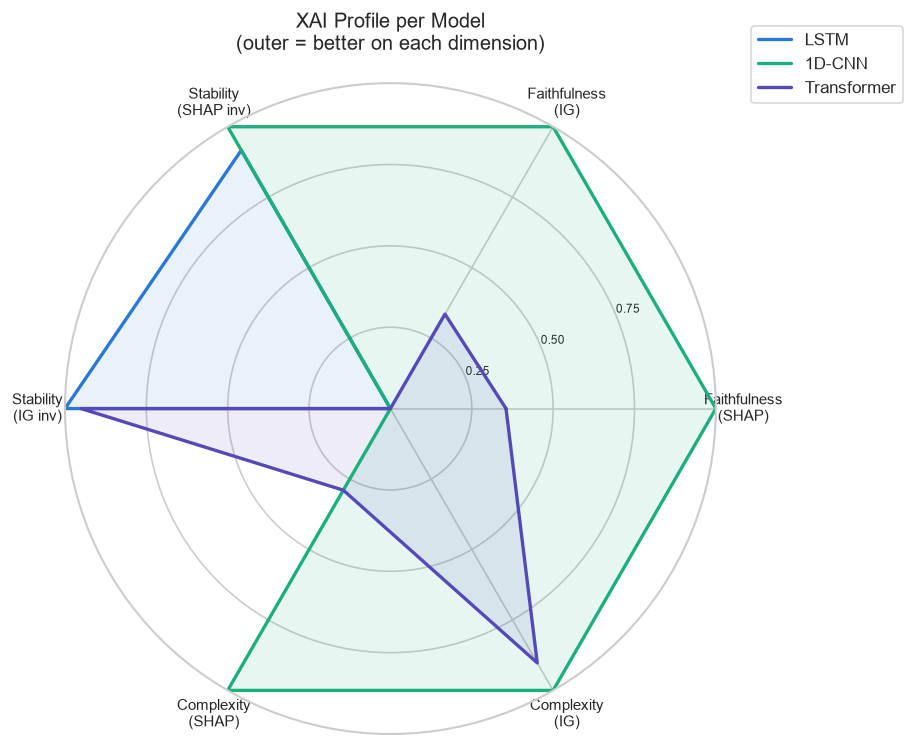

In [11]:
# Radar chart comparing SHAP results across the three models
categories = ['Faithfulness\n(SHAP)', 'Faithfulness\n(IG)',
              'Stability\n(SHAP inv)', 'Stability\n(IG inv)',
              'Complexity\n(SHAP)', 'Complexity\n(IG)']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]   # close the polygon

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

def normalise_metric(vals, higher_better=True):
    """Normalise a list of values to [0,1] for radar chart."""
    mn, mx = min(vals), max(vals)
    if mx == mn:
        return [0.5] * len(vals)
    norm = [(v - mn) / (mx - mn) for v in vals]
    return norm if higher_better else [1 - v for v in norm]

model_names = list(models.keys())
raw = {
    'faith_shap' : [faith_results[m]['shap']['peak_rmse']           for m in model_names],
    'faith_ig'   : [faith_results[m]['ig']['peak_rmse']             for m in model_names],
    'stab_shap'  : [stab_results[m]['shap']['mean_lipschitz']       for m in model_names],
    'stab_ig'    : [stab_results[m]['ig']['mean_lipschitz']         for m in model_names],
    'comp_shap'  : [comp_results[m]['shap']['mean_gini']            for m in model_names],
    'comp_ig'    : [comp_results[m]['ig']['mean_gini']              for m in model_names],
}

normalised = [
    normalise_metric(raw['faith_shap'], higher_better=True),
    normalise_metric(raw['faith_ig'],   higher_better=True),
    normalise_metric(raw['stab_shap'],  higher_better=False),  # lower = better, invert
    normalise_metric(raw['stab_ig'],    higher_better=False),
    normalise_metric(raw['comp_shap'],  higher_better=True),
    normalise_metric(raw['comp_ig'],    higher_better=True),
]

for i, model_name in enumerate(model_names):
    values = [normalised[dim][i] for dim in range(N)]
    values += values[:1]
    ax.plot(angles, values, linewidth=2, color=COLORS[model_name],
            label=LABELS[model_name])
    ax.fill(angles, values, alpha=0.1, color=COLORS[model_name])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=9)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.5, 0.75])
ax.set_yticklabels(['0.25', '0.50', '0.75'], fontsize=7)
ax.set_title('XAI Profile per Model\n(outer = better on each dimension)',
             fontsize=12, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)

plt.tight_layout()
plt.savefig(OUT_FIGURES / 'xai_eval_radar.png', bbox_inches='tight')
plt.show()

## 11 · Dissertation findings summary

In [13]:
# Auto-compute best per dimension
best_faith_shap  = LABELS[model_names[np.argmax([faith_results[m]['shap']['peak_rmse'] for m in model_names])]]
best_faith_ig    = LABELS[model_names[np.argmax([faith_results[m]['ig']['peak_rmse']   for m in model_names])]]
best_stab_shap   = LABELS[model_names[np.argmin([stab_results[m]['shap']['mean_lipschitz'] for m in model_names])]]
best_stab_ig     = LABELS[model_names[np.argmin([stab_results[m]['ig']['mean_lipschitz']   for m in model_names])]]
best_comp_shap   = LABELS[model_names[np.argmax([comp_results[m]['shap']['mean_gini']   for m in model_names])]]
best_comp_ig     = LABELS[model_names[np.argmax([comp_results[m]['ig']['mean_gini']     for m in model_names])]]

print(f"""
-------------------------------------------------------------
           XAI EVALUATION FRAMEWORK — KEY FINDINGS              
-------------------------------------------------------------
  FAITHFULNESS (peak RMSE drop when top sensors removed)         
  Best model (SHAP) : {best_faith_shap:<10}                          
  Best model (IG)   : {best_faith_ig:<10}                          
  Attribution-guided deletion > random deletion -> faithful     

  STABILITY (lower Lipschitz = more stable)                      
  Best model (SHAP) : {best_stab_shap:<10}                          
  Best model (IG)   : {best_stab_ig:<10}                          

  COMPLEXITY (higher Gini = simpler explanation)                 
  Best model (SHAP) : {best_comp_shap:<10}                          
  Best model (IG)   : {best_comp_ig:<10}                          


""")


-------------------------------------------------------------
           XAI EVALUATION FRAMEWORK — KEY FINDINGS              
-------------------------------------------------------------
  FAITHFULNESS (peak RMSE drop when top sensors removed)         
  Best model (SHAP) : 1D-CNN                              
  Best model (IG)   : 1D-CNN                              
  Attribution-guided deletion > random deletion -> faithful     

  STABILITY (lower Lipschitz = more stable)                      
  Best model (SHAP) : 1D-CNN                              
  Best model (IG)   : LSTM                                

  COMPLEXITY (higher Gini = simpler explanation)                 
  Best model (SHAP) : 1D-CNN                              
  Best model (IG)   : 1D-CNN                              



